[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ScriptsRemote/Transcend_SummerSchool/blob/main/Day4_LULC_and_Climate_with_RS/02_building_the_classification_input_es.ipynb)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Día 4 - Uso y Cobertura del Suelo y Clima con Teledetección
## Sesión 2: Construcción de la entrada de la clasificación - época seca y época húmeda

| | |
|---|---|
| **Fecha** | 2026-10-15 (jueves) |
| **Horario** | 10:40 - 12:10 |
| **Entidad** | UoM |
| **Instructores** | Christhian |

### Contenido

> Construcción de la entrada de la clasificación. Filtrado temporal, mosaicos **estacionales** sin nubes (época seca
> y época húmeda), muestras de entrenamiento y separación espacial, extracción píxel por píxel, y el
> efecto de la estación en una clasificación con Random Forest.

### Objetivos de aprendizaje

- [ ] Construir un mosaico de **época seca** y uno de **época húmeda** y explicar por qué se ven diferentes
- [ ] Apilar las dos estaciones (y el cambio de NDVI entre ellas) en una sola entrada de clasificación
- [ ] Entrenar el mismo Random Forest con tres entradas - solo seca, solo húmeda, seca + húmeda - y comparar
      los mapas, la exactitud por clase y la importancia de las variables

### Datos necesarios

- Landsat 8 y 9 Colección 2 Nivel 2 y NASADEM (catálogo de Earth Engine)
- `Assets/Day4/copacabana_samples.geojson` - muestras del
  [TRANSCEND Sample Collector](https://ee-christhianscunha.projects.earthengine.app/view/transcend-samplecollector)

### Lo que ya vimos

La sesión 1 cubrió la teoría de la clasificación y el flujo de trabajo completo con un mosaico de época
seca (cubo, muestras, división espacial, CART / SVM / Random Forest, exactitud). Aquí **repetimos
el mismo flujo de trabajo** y cambiamos solo una cosa: **la época del año de la entrada**.

---

## 2.1 - Por qué importa la estación

En el altiplano el año tiene dos mitades muy diferentes:

| | Época seca | Época húmeda |
|---|---|---|
| Meses | mayo - septiembre | noviembre - abril (las lluvias alcanzan su pico de diciembre a marzo) |
| Cielo | despejado | nubes frecuentes |
| Cultivos | cosechados, en descanso - parecen **suelo desnudo o pasto seco** | en crecimiento - **verdes** |
| Pastizal natural (pajonal) | seco, amarillo | más verde, pero cambia menos que los cultivos |

En una sola imagen de época seca, una parcela en descanso y un pastizal seco pueden tener casi la misma
reflectancia. En la época húmeda la parcela se vuelve verde. El **cambio entre las dos estaciones**
- la *fenología* - es a menudo lo que separa la agricultura de la vegetación natural.

Lo probamos con tres entradas para el **mismo** Random Forest:

1. **Seca** - solo el mosaico de época seca (como en la sesión 1);
2. **Húmeda** - solo el mosaico de época húmeda;
3. **Seca + húmeda** - ambos mosaicos apilados, más **ΔNDVI = NDVI húmeda - NDVI seca**.

Random Forest no necesita variables estandarizadas, así que usamos las bandas en sus unidades reales.

---

## 2.2 - Práctica guiada: configuración

In [4]:
# Librerías (descomente la línea de pip en un entorno nuevo, p. ej. Google Colab)
#%pip install -q earthengine-api geemap

import os
import ee                          # API de Google Earth Engine
import geemap                      # mapas interactivos para Earth Engine
import pandas as pd                # tablas (DataFrames)
import matplotlib.pyplot as plt    # gráficos

In [5]:
# Autenticar e inicializar Earth Engine
# >>> REEMPLAZAR por el id de su propio proyecto de Cloud <<<
EE_PROJECT = "ee-edwinyucra"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

In [6]:
# Área de estudio: Copacabana, en la orilla boliviana del Lago Titicaca (la misma de la sesión 1)
REGION =ee.Geometry.Polygon(
        [[[-69.10701558599568, -16.139559656552084],
          [-69.10701558599568, -16.187208792602522],
          [-69.0531139136324, -16.187208792602522],
          [-69.0531139136324, -16.139559656552084]]], None, False)

Map = geemap.Map()
Map.centerObject(REGION, 13)
Map.add_basemap("SATELLITE")
Map.addLayer(REGION, {"color": "red"}, "Study area")
Map

Map(center=[-16.16338383351134, -69.08006474980968], controls=(WidgetControl(options=['position', 'transparent…

### Las funciones del cubo de datos (del Día 3)

Las mismas tres funciones de la sesión 1: máscara de nubes, factor de escala e índices.

In [8]:
def mask_clouds(image):
    # Bits de QA_PIXEL 1 (nube dilatada), 2 (cirros), 3 (nube) y 4 (sombra de nube)
    cloud_bits = (1 << 1) | (1 << 2) | (1 << 3) | (1 << 4)
    clear = image.select("QA_PIXEL").bitwiseAnd(cloud_bits).eq(0)
    return image.updateMask(clear)


def scale_and_rename(image):
    # Factor de escala de la Colección 2 -> reflectancia de superficie, y nombres de bandas legibles
    optical = image.select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"])
    optical = optical.multiply(0.0000275).add(-0.2)
    return optical.rename(["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"])


def add_indices(image):
    ndvi = image.normalizedDifference(["NIR", "Red"]).rename("NDVI")
    ndwi = image.normalizedDifference(["Green", "NIR"]).rename("NDWI")
    ndmi = image.normalizedDifference(["NIR", "SWIR1"]).rename("NDMI")
    evi = image.expression(
        "2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)",
        {"NIR": image.select("NIR"), "RED": image.select("Red"), "BLUE": image.select("Blue")},
    ).rename("EVI")
    msavi = image.expression(
        "(2 * NIR + 1 - sqrt((2 * NIR + 1) ** 2 - 8 * (NIR - RED))) / 2",
        {"NIR": image.select("NIR"), "RED": image.select("Red")},
    ).rename("MSAVI")
    return image.addBands([ndvi, msavi, evi, ndwi, ndmi])

---

## 2.3 - Mosaicos estacionales

Una función construye el mosaico de mediana de cualquier período. Usamos el **año agrícola
2023/24**: la época húmeda que precede a la época seca de 2024, de modo que ambos mosaicos muestran el mismo
ciclo de cultivo.

> La época húmeda es nublada. El filtro de nubes es más permisivo (60%) y la ventana es más amplia
> (noviembre - abril) para que queden suficientes píxeles despejados. Verifique cuántas imágenes entran en cada
> mosaico.

In [9]:
def seasonal_mosaic(start, end, max_cloud):
    # Landsat 8 + 9 de un período: filtrar, limpiar, escalar, agregar índices y tomar la mediana
    collection = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
                    .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
                    .filterBounds(REGION)
                    .filterDate(start, end)
                    .filter(ee.Filter.lt("CLOUD_COVER", max_cloud))
                    .map(mask_clouds)
                    .map(scale_and_rename)
                    .map(add_indices))
    print(f"{start} to {end}: {collection.size().getInfo()} images")
    return collection.median().clip(REGION)


dry = seasonal_mosaic("2024-05-01", "2024-10-01", max_cloud=30)   # época seca
wet = seasonal_mosaic("2023-11-01", "2024-05-01", max_cloud=60)   # época húmeda

2024-05-01 to 2024-10-01: 18 images
2023-11-01 to 2024-05-01: 15 images


In [10]:
# Visualización: color natural y NDVI
vis_rgb = {"bands": ["Red", "Green", "Blue"], "min": 0.0, "max": 0.3}
vis_ndvi = {"bands": ["NDVI"], "min": 0.0, "max": 0.7,
            "palette": ["#a6611a", "#f5f5dc", "#a6d96a", "#1a9641", "#00441b"]}

# Mapa dividido: época seca a la izquierda, época húmeda a la derecha (arrastre la barra)
Map = geemap.Map()
Map.centerObject(REGION, 14)
Map.split_map(left_layer=geemap.ee_tile_layer(dry, vis_rgb, "Dry season (RGB)"),
              right_layer=geemap.ee_tile_layer(wet, vis_rgb, "Wet season (RGB)"),
              left_label="Dry season", right_label="Wet season")
Map

Map(center=[-16.163383833511336, -69.0800647498097], controls=(ZoomControl(options=['position', 'zoom_in_text'…

In [11]:
# La misma comparación con el NDVI: ¿dónde se vuelve verde la vegetación en la época húmeda?
Map = geemap.Map()
Map.centerObject(REGION, 14)
Map.split_map(left_layer=geemap.ee_tile_layer(dry, vis_ndvi, "Dry season (NDVI)"),
              right_layer=geemap.ee_tile_layer(wet, vis_ndvi, "Wet season (NDVI)"),
              left_label="Dry season - NDVI", right_label="Wet season - NDVI")
Map.add_colorbar(vis_ndvi, label="NDVI")
Map

### La entrada de la clasificación: una pila con ambas estaciones

Agregamos el sufijo `_dry` o `_wet` a cada banda, calculamos el **ΔNDVI** (húmeda menos seca) y agregamos
la elevación y la pendiente. Luego anotamos qué bandas usa cada una de las tres entradas.

In [12]:
# Nombres de las bandas con la estación como sufijo
dry_s = dry.rename(dry.bandNames().map(lambda b: ee.String(b).cat("_dry")))
wet_s = wet.rename(wet.bandNames().map(lambda b: ee.String(b).cat("_wet")))

# Cambio de NDVI entre las estaciones: valores altos = fuerte reverdecimiento en la época húmeda
delta_ndvi = wet.select("NDVI").subtract(dry.select("NDVI")).rename("dNDVI")

# Terreno (NASADEM)
elevation = ee.Image("NASA/NASADEM_HGT/001").select("elevation")
slope = ee.Terrain.slope(elevation).rename("slope")

# Una imagen con todo
stack = dry_s.addBands([wet_s, delta_ndvi, elevation, slope]).toFloat()

# Las tres entradas: las mismas bandas de terreno, diferentes estaciones
DRY_BANDS = dry_s.bandNames().getInfo()
WET_BANDS = wet_s.bandNames().getInfo()
INPUTS = {
    "Dry": DRY_BANDS + ["elevation", "slope"],
    "Wet": WET_BANDS + ["elevation", "slope"],
    "Dry + wet": DRY_BANDS + WET_BANDS + ["dNDVI", "elevation", "slope"],
}

for name, bands in INPUTS.items():
    print(f"{name:10s}: {len(bands)} features")

Dry       : 13 features
Wet       : 13 features
Dry + wet : 25 features


In [16]:
# Mapa de ΔNDVI: verde = reverdece en la época húmeda (cultivos, pastizal húmedo), marrón = sin cambio
vis_dndvi = {"min": -0.1, "max": 0.3, "palette": ["#8c510a", "#f5f5f5", "#1a9641"]}

Map = geemap.Map()
Map.centerObject(REGION, 14)
Map.add_basemap("SATELLITE")
Map.addLayer(delta_ndvi, vis_dndvi, "ΔNDVI (wet - dry)")
Map.add_colorbar(vis_dndvi, label="ΔNDVI (wet - dry)")
Map

---

## 2.4 - Muestras, entrenamiento y prueba

Las mismas muestras y la misma separación espacial de la sesión 1. Como extraemos todas las bandas
de la pila **una sola vez**, las tres entradas se entrenan y se prueban exactamente con los mismos píxeles -
la comparación es justa.

> **Muestras y estaciones.** Las etiquetas deben ser verdaderas en ambas estaciones. Las clases de *uso* del suelo
> como la agricultura son estables, pero la orilla del lago y las áreas inundadas cambian entre estaciones -
> evite muestras justo en el borde del agua.

In [18]:
# >>> Ajuste a su archivo <<<
SAMPLES_FILE = "/content/copacabana_samples.geojson"
SAMPLES_URL = ("https://raw.githubusercontent.com/ScriptsRemote/Transcend_SummerSchool/"
               "main/Assets/Day4/copacabana_samples.geojson")   # usado en Colab
CLASS_PROPERTY = "class"          # atributo con el código de la clase (número)
NAME_PROPERTY = "class_name"      # atributo con el nombre de la clase

# GeoJSON -> ee.FeatureCollection (archivo local si existe, si no desde GitHub)
samples = geemap.coreutils.geojson_to_ee(SAMPLES_FILE if os.path.exists(SAMPLES_FILE) else SAMPLES_URL)

# Códigos, nombres y colores de las clases (agua, vegetación, suelo, urbano, agricultura)
classes = (geemap.ee_to_df(samples)[[CLASS_PROPERTY, NAME_PROPERTY]]
           .drop_duplicates().sort_values(CLASS_PROPERTY).reset_index(drop=True))
CLASS_CODES = classes[CLASS_PROPERTY].astype(int).tolist()
CLASS_NAMES = classes[NAME_PROPERTY].tolist()
PALETTE = ["#2c7bb6", "#a21616", "#d8b365", "#2ae01a", "#cc7218f3"]


print("Samples:", samples.size().getInfo())
classes

Samples: 488


,class,class_name
0,1,water
1,2,urban
2,3,agriculture
3,4,vegetation
4,5,soil


In [15]:
# División aleatoria 70 / 30 de las muestras
samples = samples.randomColumn("random", seed=42)
train_samples = samples.filter(ee.Filter.lt("random", 0.7))
test_samples = samples.filter(ee.Filter.gte("random", 0.7))

# Separación espacial: descartar las muestras de entrenamiento a menos de MIN_DISTANCE de una muestra de prueba
MIN_DISTANCE = 110   # metros - mayor que el espaciamiento de 100 m de la grilla de muestras
too_close = ee.Filter.withinDistance(distance=MIN_DISTANCE, leftField=".geo",
                                     rightField=".geo", maxError=10)
train_samples = ee.Join.inverted().apply(train_samples, test_samples, too_close)

# Valores de los píxeles de TODAS las bandas de la pila bajo cada muestra
train = stack.sampleRegions(collection=train_samples, properties=[CLASS_PROPERTY],
                            scale=30, tileScale=4)
test = stack.sampleRegions(collection=test_samples, properties=[CLASS_PROPERTY],
                           scale=30, tileScale=4)

pd.DataFrame({"train": train.aggregate_histogram(CLASS_PROPERTY).getInfo(),
              "test": test.aggregate_histogram(CLASS_PROPERTY).getInfo()})

,train,test
1,49,46
2,11,15
3,18,30
4,6,9
5,37,27


### Lo que dicen las muestras: NDVI por clase en cada estación

Antes de clasificar, observe la tabla de entrenamiento. Si una clase cambia mucho entre las estaciones
y otra no, la entrada estacional ayudará a separarlas.

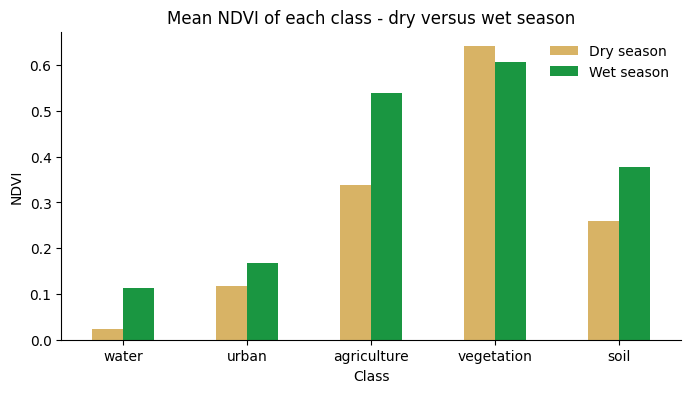

In [ ]:
# NDVI medio de cada clase en la época seca y en la húmeda (píxeles de entrenamiento)
df_train = geemap.ee_to_df(train)
ndvi_class = df_train.groupby(CLASS_PROPERTY)[["NDVI_dry", "NDVI_wet"]].mean()
ndvi_class.index = ndvi_class.index.astype(int).map(dict(zip(CLASS_CODES, CLASS_NAMES)))

ax = ndvi_class.plot.bar(figsize=(8, 4), rot=0, color=["#d8b365", "#1a9641"])
ax.set_title("Mean NDVI of each class - dry versus wet season")
ax.set_xlabel("Class")
ax.set_ylabel("NDVI")
ax.legend(["Dry season", "Wet season"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

---

## 2.5 - El mismo Random Forest, tres entradas

Una función entrena el Random Forest con una lista de bandas, clasifica la imagen y la evalúa
con las muestras de prueba. La llamamos tres veces y mostramos los mapas uno debajo del otro.

In [19]:
vis_classes = {"min": min(CLASS_CODES), "max": max(CLASS_CODES), "palette": PALETTE}


def classify_season(bands):
    # Entrenar el Random Forest con las bandas elegidas
    rf = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(
        features=train, classProperty=CLASS_PROPERTY, inputProperties=bands)
    # Mapa clasificado y matriz de confusión sobre las muestras de prueba
    classified = stack.select(bands).classify(rf)
    cm = test.classify(rf).errorMatrix(CLASS_PROPERTY, "classification", CLASS_CODES)
    return rf, classified, cm


def show_classification(classified, background, title):
    m = geemap.Map()
    m.centerObject(REGION, 14)
    m.addLayer(background, vis_rgb, "RGB", False)
    m.addLayer(classified, vis_classes, title)
    m.add_legend(title=title, legend_dict=dict(zip(CLASS_NAMES, PALETTE)))
    return m


results = {name: classify_season(bands) for name, bands in INPUTS.items()}

### Solo época seca

In [20]:
show_classification(results["Dry"][1], dry, "Random Forest - dry season")

Map(center=[-16.163383833511336, -69.0800647498097], controls=(WidgetControl(options=['position', 'transparent…

### Solo época húmeda

In [21]:
show_classification(results["Wet"][1], wet, "Random Forest - wet season")

Map(center=[-16.163383833511336, -69.0800647498097], controls=(WidgetControl(options=['position', 'transparent…

### Época seca + húmeda (y ΔNDVI)

In [22]:
show_classification(results["Dry + wet"][1], dry, "Random Forest - dry + wet")

Map(center=[-16.163383833511336, -69.0800647498097], controls=(WidgetControl(options=['position', 'transparent…

In [23]:
# Clasificaciones Random Forest lado a lado: seca, húmeda y seca + húmeda - los tres mapas se mueven juntos
import ipywidgets as widgets
import ipyleaflet

center = REGION.centroid(maxError=1).coordinates().getInfo()[::-1]   # [lat, lon]
names = ["Dry", "Wet", "Dry + wet"]

grid = widgets.GridspecLayout(1, 3, height="400px")
maps = []

for j, name in enumerate(names):
    # El mismo mapa que crea linked_maps, colocado directamente en la grilla
    m = geemap.Map(center=center, zoom=14, height="400px", lite_mode=True, add_google_map=False)
    m.addLayer(results[name][1], vis_classes, f"RF - {name}")
    m.add(ipyleaflet.WidgetControl(widget=widgets.Label(f"RF - {name}"), position="topright"))

    # Vincular el zoom y la posición al primer mapa
    maps.append(m)
    widgets.jslink((maps[0], "center"), (m, "center"))
    widgets.jslink((maps[0], "zoom"), (m, "zoom"))
    grid[0, j] = m

grid

GridspecLayout(children=(Map(center=[-16.163384962246813, -69.08006474980968], controls=(WidgetControl(options…

### Lectura de los tres mapas - qué dice la literatura

**1. Algunas clases no dependen de la estación.** El agua, el núcleo urbano de Copacabana y el
suelo desnudo de las colinas del sur se ven iguales en los tres mapas. Son espectralmente distintos
todo el año, así que una buena imagen es suficiente para ellos. La información de varias fechas importa sobre todo para
las clases que **cambian en el tiempo** - la vegetación y los cultivos (Gómez et al., 2016).

**2. El mapa de época húmeda se vuelve más verde.** Muchos más píxeles se clasifican como *vegetación* en la
planicie y en las colinas. En la época de lluvias el pastizal nativo (pajonal) y los cultivos están
ambos fotosintéticamente activos, así que el "verde" deja de ser una característica de una sola clase. El
ciclo estacional - la **fenología** - es justamente la información que las series temporales aportan al mapeo
de la cobertura del suelo (Gómez et al., 2016; Inglada et al., 2017), pero un solo mosaico de época húmeda muestra
solo **un momento** de ese ciclo. Con pocas muestras de vegetación, el modelo tiende a llamar "vegetación" a todo
píxel verde (error de comisión).

**3. Seca + húmeda da el mapa más conservador.** Es parecido al mapa de época seca, con menos ruido de píxeles aislados
que el de época húmeda. Apilar composiciones estacionales como variables de un Random Forest es la estrategia
usada en grandes productos operativos construidos en Earth Engine, como el mapa europeo de cobertura del suelo
ELC10 (Venter & Sydenham, 2021) y las colecciones de MapBiomas (Souza et al., 2020).

**4. Una línea delgada de "urbano" a lo largo de la orilla del lago.** Aparece en los tres mapas. Un píxel de 30 m en
la orilla mezcla agua, arena húmeda y piedras, y su espectro promedio no se parece a ninguna clase pura -
el problema clásico del **píxel mixto** (Fisher, 1997). Explica parte de la baja exactitud de
la clase urbana.

**5. La época húmeda tiene menos observaciones, y de peor calidad.** El mosaico de época húmeda se construyó con menos
imágenes (ver la sección 2.3), y las nubes durante la temporada de crecimiento son un límite conocido de los sensores
ópticos para el mapeo agrícola (Whitcraft et al., 2015). Menos observaciones limpias significan una
mediana más ruidosa y más efecto "sal y pimienta" en el mapa.

**Compare los tres mapas.** ¿Dónde cambia la agricultura? Observe las laderas de las colinas y
la planicie cerca del lago: las parcelas que el mapa de época seca confunde con suelo o vegetación a menudo aparecen
correctamente cuando se agrega la época húmeda.

---

## 2.6 - ¿Qué entrada funciona mejor?

Las mismas muestras de prueba para las tres entradas.

In [24]:
# Exactitud global y Kappa de cada entrada
summary = pd.DataFrame({
    name: {"Overall accuracy": cm.accuracy().getInfo(), "Kappa": cm.kappa().getInfo()}
    for name, (rf, classified, cm) in results.items()
}).T
summary.round(3)

,Overall accuracy,Kappa
Dry,0.945,0.926
Wet,0.961,0.947
Dry + wet,0.929,0.904


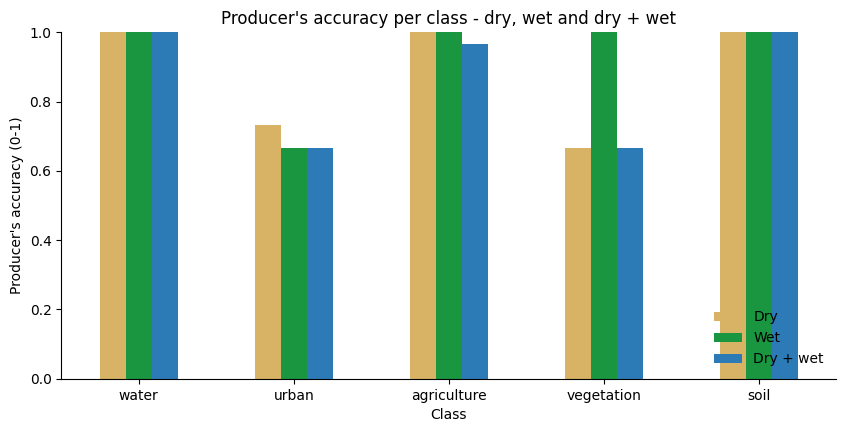

,Dry,Wet,Dry + wet
water,1.00,1.00,1.00
urban,0.73,0.67,0.67
agriculture,1.00,1.00,0.97
vegetation,0.67,1.00,0.67
soil,1.00,1.00,1.00


In [25]:
# Exactitud del productor por clase para cada entrada
producers = pd.DataFrame({
    name: cm.producersAccuracy().project([0]).getInfo()
    for name, (rf, classified, cm) in results.items()
}, index=CLASS_NAMES)

ax = producers.plot.bar(figsize=(10, 4.5), rot=0, color=["#d8b365", "#1a9641", "#2c7bb6"])
ax.set_title("Producer's accuracy per class - dry, wet and dry + wet")
ax.set_xlabel("Class")
ax.set_ylabel("Producer's accuracy (0-1)")
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

producers.round(2)

**Cómo leerlo.** La exactitud global puede cambiar solo un poco, porque el agua y lo urbano
son fáciles en cualquier estación. Observe las clases **agricultura** y **vegetación**: ahí es donde
la estación marca la diferencia.

### ¿Por qué "seca + húmeda" no ganó aquí? Una lección sobre la evaluación

En nuestra ejecución la exactitud global fue de aproximadamente **0.95 (seca), 0.96 (húmeda) y 0.93 (seca + húmeda)** - la
entrada con más información quedó última. Esto no contradice la teoría; es una
lección sobre los **datos**:

- **El conjunto de prueba es pequeño.** Unos 130 píxeles de prueba en total, y solo 9 de *vegetación*: un
  píxel más o menos cambia la exactitud del productor de esa clase en ~11 puntos. Diferencias de
  1-3 puntos en la exactitud global están dentro de la incertidumbre del muestreo. Para afirmar que un
  clasificador es mejor que otro, la muestra de prueba debe ser mucho más grande (Foody, 2009), y
  la exactitud siempre debe informarse con un **intervalo de confianza** (Olofsson et al., 2014).
- **El conjunto de entrenamiento es pequeño y desbalanceado.** Solo 6 píxeles de entrenamiento de *vegetación* para 25
  variables. Random Forest es robusto, pero la cantidad y la calidad de los datos de entrenamiento importan más
  que el algoritmo o sus parámetros (Pelletier et al., 2016; Belgiu & Drăguţ, 2016; Maxwell
  et al., 2018). Agregar variables sin agregar muestras puede empeorar el modelo.
- **La señal estacional ayuda solo si las muestras la representan.** La fenología separa los cultivos
  del pastizal cuando ambas clases están bien muestreadas en las estaciones usadas.

La celda siguiente calcula el intervalo de confianza del 95% de la exactitud global de cada entrada.

In [26]:
# Intervalo de confianza del 95% de la exactitud global: OA ± 1.96 * sqrt(OA * (1 - OA) / n)
n_test = test.size().getInfo()
ci = summary[["Overall accuracy"]].copy()
ci["± 95% CI"] = 1.96 * (ci["Overall accuracy"] * (1 - ci["Overall accuracy"]) / n_test) ** 0.5
ci["lower"] = ci["Overall accuracy"] - ci["± 95% CI"]
ci["upper"] = ci["Overall accuracy"] + ci["± 95% CI"]

print("Test pixels:", n_test)
ci.round(3)

Test pixels: 127


,Overall accuracy,± 95% CI,lower,upper
Dry,0.945,0.040,0.905,0.985
Wet,0.961,0.034,0.927,0.994
Dry + wet,0.929,0.045,0.885,0.974


Si los intervalos **se superponen**, las tres entradas son estadísticamente equivalentes con este conjunto de prueba.
Para responder realmente "¿ayuda la época húmeda?", recolecte más muestras - sobre todo de
*vegetación* y *agricultura* - y vuelva a hacer la comparación (ejercicio 4 más abajo).

### ¿Qué variables usó el modelo seca + húmeda?

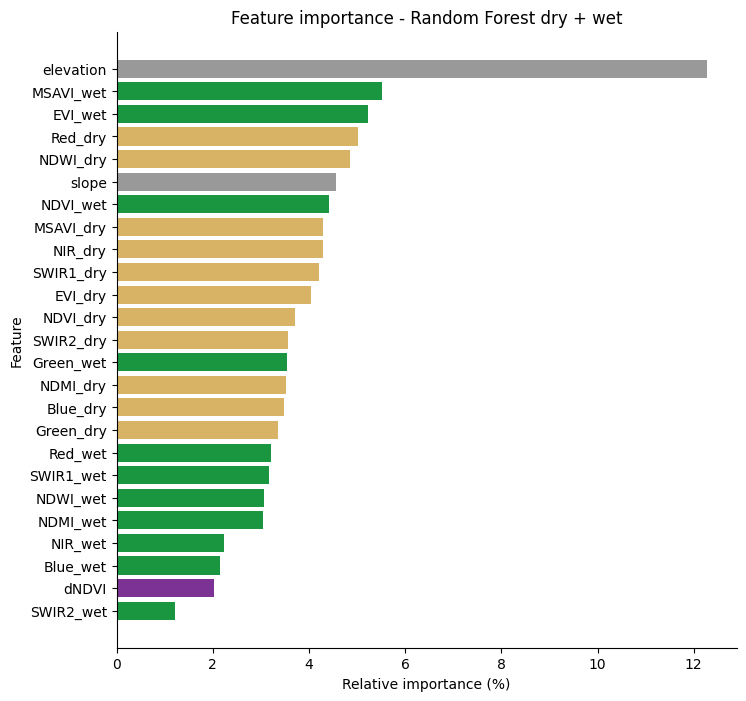

In [27]:
# Importancia de las variables del Random Forest seca + húmeda
rf_both = results["Dry + wet"][0]
importance = pd.Series(ee.Dictionary(rf_both.explain()).get("importance").getInfo())
importance = (100 * importance / importance.sum()).sort_values()

# Color por estación: marrón = seca, verde = húmeda, morado = ΔNDVI, gris = terreno
colours = ["#d8b365" if b.endswith("_dry") else "#1a9641" if b.endswith("_wet")
           else "#7b3294" if b == "dNDVI" else "#999999" for b in importance.index]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importance.index, importance.values, color=colours)
ax.set_title("Feature importance - Random Forest dry + wet")
ax.set_xlabel("Relative importance (%)")
ax.set_ylabel("Feature")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Las barras marrones son bandas de época seca, las barras verdes bandas de época húmeda, la morada es el ΔNDVI y las grises son
el terreno. Si las bandas de época húmeda y el ΔNDVI están cerca de la parte superior, el modelo está usando el **cambio
estacional** para separar las clases - exactamente la información que una sola imagen de época seca no tiene.

> **Cuidado con las nubes.** Los píxeles sin una observación despejada en la época húmeda quedan enmascarados en el mosaico
> de época húmeda, así que quedan sin clase en los mapas *Húmeda* y *Seca + húmeda*. Si ve huecos, amplíe
> la ventana de la época húmeda o suba el filtro de nubes.

---

## 2.7 - Ejercicio

1. **Otra división de estaciones.** Use solo el pico de las lluvias (enero - marzo) para el mosaico de
   época húmeda. ¿Cuántas imágenes quedan, y qué pasa con la exactitud?
2. **Menos bandas.** Entrene un modelo solo con `NDVI_dry`, `NDVI_wet`, `dNDVI`, `elevation` y
   `slope`. ¿Es mucho peor que el modelo completo seca + húmeda?
3. **Otro año.** Construya los mosaicos para el año agrícola 2022/23 y clasifique con las
   mismas muestras. ¿Las parcelas agrícolas se mantienen en el mismo lugar?
4. **Más muestras.** Recolecte al menos 30 muestras más de *vegetación* y *agricultura* en el
   Sample Collector, vuelva a ejecutar el notebook y compare de nuevo los intervalos de confianza de la sección 2.6.
   ¿Ahora *seca + húmeda* queda primero?

**Entregable**: la tabla de exactitud global de las tres entradas, el gráfico de exactitud
del productor y un párrafo corto explicando qué clases se beneficiaron de la época húmeda.

---

## Referencias

- Gómez, C., White, J. C., Wulder, M. A. (2016). Optical remotely sensed time series data for
  land cover classification: a review. *ISPRS Journal of Photogrammetry and Remote Sensing*,
  116, 55-72. <https://doi.org/10.1016/j.isprsjprs.2016.03.008>
- Belgiu, M., Drăguţ, L. (2016). Random forest in remote sensing: a review of applications and
  future directions. *ISPRS Journal of Photogrammetry and Remote Sensing*, 114, 24-31.
  <https://doi.org/10.1016/j.isprsjprs.2016.01.011>
- Inglada, J. et al. (2017). Operational high resolution land cover map production at the
  country scale using satellite image time series. *Remote Sensing*, 9(1), 95.
  <https://doi.org/10.3390/rs9010095>
- Venter, Z. S., Sydenham, M. A. K. (2021). Continental-scale land cover mapping at 10 m
  resolution over Europe (ELC10). *Remote Sensing*, 13(12), 2301.
  <https://doi.org/10.3390/rs13122301>
- Souza, C. M. et al. (2020). Reconstructing three decades of land use and land cover changes in
  Brazilian biomes with Landsat archive and Earth Engine. *Remote Sensing*, 12(17), 2735.
  <https://doi.org/10.3390/rs12172735>
- Pelletier, C. et al. (2016). Assessing the robustness of Random Forests to map land cover with
  high resolution satellite image time series over large areas. *Remote Sensing of
  Environment*, 187, 156-168. <https://www.sciencedirect.com/science/article/pii/S0034425716303820>
- Whitcraft, A. K., Vermote, E. F., Becker-Reshef, I., Justice, C. O. (2015). Cloud cover
  throughout the agricultural growing season: impacts on passive optical earth observations.
  *Remote Sensing of Environment*, 156, 438-447.
  <https://www.sciencedirect.com/science/article/abs/pii/S0034425714004179>
- Fisher, P. (1997). The pixel: a snare and a delusion. *International Journal of Remote
  Sensing*, 18(3), 679-685. <https://ui.adsabs.harvard.edu/abs/1997IJRS...18..679F>
- Foody, G. M. (2009). Sample size determination for image classification accuracy assessment
  and comparison. *International Journal of Remote Sensing*, 30(20), 5273-5291.
  <https://doi.org/10.1080/01431160903130937>
- Olofsson, P. et al. (2014). Good practices for estimating area and assessing accuracy of land
  change. *Remote Sensing of Environment*, 148, 42-57.
  <https://ui.adsabs.harvard.edu/abs/2014RSEnv.148...42O/abstract>
- Maxwell, A. E., Warner, T. A., Fang, F. (2018). Implementation of machine-learning
  classification in remote sensing: an applied review. *International Journal of Remote
  Sensing*, 39(9), 2784-2817. <https://doi.org/10.1080/01431161.2018.1433343>
- Earth Engine - clasificación supervisada:
  <https://developers.google.com/earth-engine/guides/classification>
- Mapas divididos de geemap: <https://geemap.org>